# 05 — OBIS and Bio-ORACLE integration with spatial screening

**Project:** OCEAVERA  
**Branch:** <code>pipeline/data-integration-and-data-cleaning</code>  
**Review date:** 16 October 2026

This notebook shows how the cleaned OBIS occurrence data and selected Bio-ORACLE environmental layers were joined, then how the integrated records were screened and summarized spatially.

## Contributors

| Registration Number | Member Name | GitHub Account |
| --- | --- | --- |
| IT24103038 | Adithya Gunawardana | AdithyaGunawardana |
| IT24100184 | Ushan Srinuka | Ushan-Srinuka |

## Purpose and scope

The notebook presents the two source datasets separately, their time and raster-cell matching, the combined environmental coverage, the D-054 Policy B marine water-centre candidates and the resulting grid summary.

It documents Adithya's allocated dataset integration and integrated-data cleaning work and Ushan's allocated spatial integration work. It reads saved local data and records. It does not rerun either processing script, reopen Bio-ORACLE NetCDF arrays, or change datasets or filtering decisions.

## 1. Dataset A — OBIS occurrences

The biological input is the cleaned Area 230 OBIS table at <code>data/interim/obis/cleaning/occurrences_cleaned.csv</code>. It contains 23,371 occurrence records and 112 original OBIS fields.

The integration keeps each occurrence and its source-row identity. OBIS date fields determine whether the occurrence can be assigned to one of the available environmental time slices. The original quality flags and coordinate-uncertainty fields remain available for later spatial screening.

## 2. Dataset B — Bio-ORACLE environmental layers

The environmental input is the selected subset of the cleaned Bio-ORACLE catalogue. The integration manifest lists 106 selected products: 55 baseline products, 50 SSP245 products and one static terrain product. Those products describe 139 source variable names and contribute 382 output feature definitions. The cleaning record also preserves an unresolved source marine-mask convention and one missing value inside its candidate domain; neither is used as marine-location evidence.

Baseline environmental coordinates are labelled 2000 and 2010. The SSP245 products use their 2020 coordinate for observations from 2020–2026. Static terrain values are not treated as dated observations. Some source definitions are retained in the schema but quarantined as null where the original metadata does not justify a numerical correction.

## 3. How the datasets were integrated

Script 08 assigns each OBIS occurrence to a supported environmental period when its resolved date allows it, then matches its coordinates to the nearest in-extent Bio-ORACLE grid-cell centre. NetCDF masks and scale/offset metadata were handled by netCDF4 during the completed integration; they are not reapplied here.

| OBIS period | Bio-ORACLE slice used |
| --- | --- |
| 2000–2009 | Baseline coordinate 2000 |
| 2010–2019 | Baseline coordinate 2010 |
| 2020–2026 | SSP245 coordinate 2020, used as a decadal approximation |
| No supported period | No time-dependent slice |

The source raster axes contain 178 latitude rows and 165 longitude columns. A matched cell establishes a technical coordinate match; it does not establish that the occurrence is marine.

## 4. Spatial integration and Policy B

The spatial reference is the positive marine-water polygon prepared from GSHHG 2.3.7 and saved as <code>data/interim/geography/sri_lanka_marine_water.gpkg</code>. Script 09 uses recorded OBIS point locations and quality flags to create current marine water-centre candidates.

Policy B requires an eligible date, a valid flags array without the exact <code>ON_LAND</code> or <code>MARINE_UNSURE</code> tokens, and a point strictly inside the GSHHG water polygon. Coordinate-uncertainty footprints remain separately classified. A centre inside water does not prove the entire uncertainty footprint is marine.

## 5. Outputs and scientific limits

The branch publishes a full integration archive, a temporal subset, Policy B candidates, individual grid observations and a species/cell/period summary. The summary includes only records with a species rank and taxonomic identifier. Repeated occurrences are record counts, not abundance.

The collection rectangle is not an EEZ or final modelling domain. Environmental extraction does not establish marine validity, feature suitability or annual conditions. Species choice, predictors, targets, background design, validation and modelling remain outside this branch.

## 6. Notebook execution

Run the Code cells in order with the existing WSL <code>OCEAVERA</code> Python 3.14.8 environment. The default run is offline. The notebook reads saved inputs and reports into memory and does not write dataset files.

The repository-root lookup works when Jupyter starts from the repository root or from this notebook folder. Graphs are descriptive summaries of the recorded inputs and outputs, not ecological-causation claims.

## 7. Load saved inputs, outputs and evidence

This first cell reads the cleaned OBIS CSV, five current GeoParquets, the GSHHG reference polygon and the existing integration, Policy B and independent-verification reports.

In [27]:
from importlib import metadata
import hashlib
import json
from pathlib import Path
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "PROJECT_REQUIREMENTS.md").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the OCEAVERA repository.")

DATA = ROOT / "data" / "interim" / "integrated"
RECORDS = ROOT / "docs" / "records"

integration_manifest = json.loads(
    (RECORDS / "2026-10-16-integration-manifest.json").read_text()
)
policy_report = json.loads(
    (RECORDS / "2026-10-16-policy-b-execution-report.json").read_text()
)
source_audit = json.loads(
    (RECORDS / "2026-10-16-independent-environmental-verification.json").read_text()
)

obis_path = ROOT / integration_manifest["sources"]["obis_csv"]
obis_input = pd.read_csv(obis_path, low_memory=False)

full = gpd.read_parquet(DATA / "full" / "integrated_observations.parquet")
temporal = gpd.read_parquet(DATA / "temporal" / "observations_2000_2026.parquet")
marine = gpd.read_parquet(DATA / "marine" / "marine_observations.parquet")
grid = gpd.read_parquet(DATA / "gridded" / "grid_observations.parquet")
summary = gpd.read_parquet(DATA / "gridded" / "species_cell_period_summary.parquet")
water_reference = gpd.read_file(
    ROOT / "data" / "interim" / "geography" / "sri_lanka_marine_water.gpkg"
)

sns.set_theme(style="whitegrid")
versions = pd.DataFrame({
    "Component": ["Python", "pandas", "GeoPandas", "PyArrow", "Matplotlib", "Seaborn", "netCDF4"],
    "Version": [
        sys.version.split()[0],
        metadata.version("pandas"),
        metadata.version("geopandas"),
        metadata.version("pyarrow"),
        metadata.version("matplotlib"),
        metadata.version("seaborn"),
        metadata.version("netCDF4"),
    ],
})
print("Repository:", ROOT.name)
print("Notebook working folder:", Path.cwd().relative_to(ROOT).as_posix())
display(versions)

Repository: OCEAVERA
Notebook working folder: notebooks/branch_work


,Component,Version
0,Python,3.14.8
1,pandas,3.0.6
2,GeoPandas,1.2.0
3,PyArrow,26.0.0
4,Matplotlib,3.11.2
5,Seaborn,0.13.2
6,netCDF4,1.7.4


## 8. OBIS contribution and time assignment

The table describes the cleaned biological input and its row/field presence in the integration schema. The chart shows how many OBIS rows received each environmental source period. Records without a supported period remain in the full archive but do not receive a time-dependent environmental slice.

,Measure,Count
0,Cleaned OBIS records,23371
1,Original OBIS fields,112
2,Original fields present in integrated schema,112
3,Unique integration source-row identities,23371
4,Rows with a supported environmental period,9681
5,Rows with no supported period,13690
6,Distinct source raster cells before filtering,965


,OBIS time assignment,Records
0,2000–2009 → baseline 2000,651
1,2010–2019 → baseline 2010,2564
2,2020–2026 → SSP245 2020,6466
3,No supported source period,13690


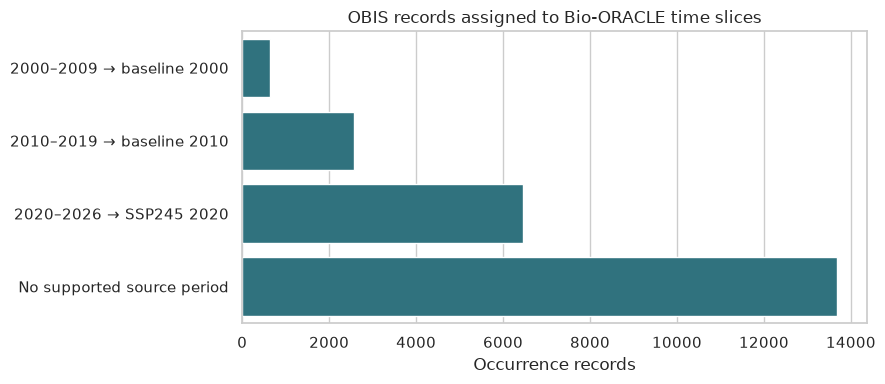

In [28]:
obis_fields = obis_input.columns.tolist()
obis_profile = pd.DataFrame({
    "Measure": [
        "Cleaned OBIS records",
        "Original OBIS fields",
        "Original fields present in integrated schema",
        "Unique integration source-row identities",
        "Rows with a supported environmental period",
        "Rows with no supported period",
        "Distinct source raster cells before filtering",
    ],
    "Count": [
        len(obis_input),
        len(obis_fields),
        sum(field in full.columns for field in obis_fields),
        full["integration_source_row"].nunique(),
        full["environment_period"].notna().sum(),
        full["environment_period"].isna().sum(),
        full["raster_cell_id"].nunique(),
    ],
})
display(obis_profile)

period_names = {
    "baseline_2000": "2000–2009 → baseline 2000",
    "baseline_2010": "2010–2019 → baseline 2010",
    "ssp245_2020": "2020–2026 → SSP245 2020",
}
assignment_order = list(period_names.values()) + ["No supported source period"]
assignment_labels = full["environment_period"].map(period_names).fillna(
    "No supported source period"
)
assignments = (
    assignment_labels.value_counts()
    .reindex(assignment_order, fill_value=0)
    .rename_axis("OBIS time assignment")
    .reset_index(name="Records")
)
display(assignments)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=assignments, x="Records", y="OBIS time assignment", ax=ax, color="#237b8b")
ax.set(title="OBIS records assigned to Bio-ORACLE time slices",
       xlabel="Occurrence records", ylabel="")
plt.tight_layout()
plt.show()

## 9. Bio-ORACLE product and feature profile

The product chart separates historical baseline, SSP245 and static terrain products. The feature chart shows supported feature definitions by time slice after source-semantic quarantines. The output schema retains all 382 definitions, including 10 static terrain features; these slice counts are not annual measurements.

,Product family,Products
0,Baseline,55
1,SSP245,50
2,Static terrain,1


,Bio-ORACLE slice,Usable feature definitions
0,Baseline 2000,334
1,Baseline 2010,334
2,SSP245 2020,350


Products in cleaned catalogue: 356
Selected source products: 106
Distinct source variables: 139
Environmental feature definitions in output: 382


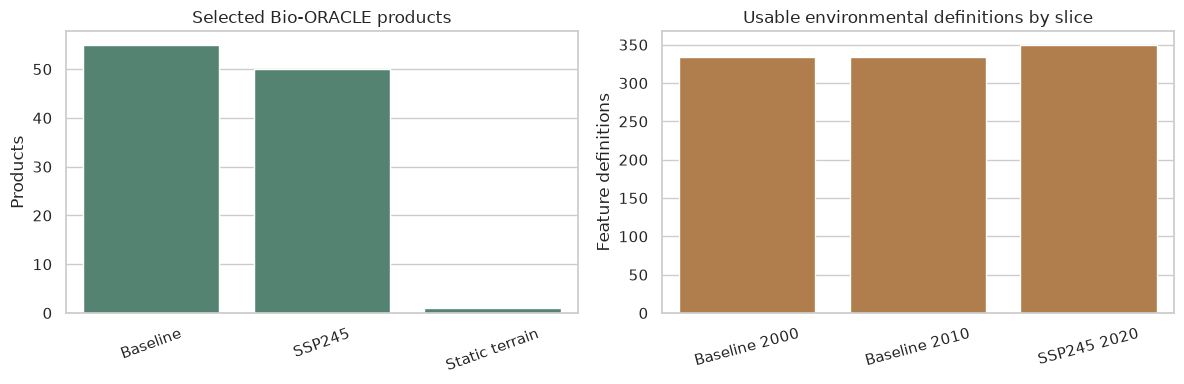

In [29]:
sources = integration_manifest["sources"]
product_counts = pd.DataFrame({
    "Product family": ["Baseline", "SSP245", "Static terrain"],
    "Products": [
        sources["selected_source_counts"]["baseline"],
        sources["selected_source_counts"]["ssp245"],
        sources["selected_source_counts"]["terrain"],
    ],
})
usable_features = integration_manifest["usable_features_by_period"]
feature_counts = pd.DataFrame({
    "Bio-ORACLE slice": ["Baseline 2000", "Baseline 2010", "SSP245 2020"],
    "Usable feature definitions": [
        usable_features["baseline_2000"],
        usable_features["baseline_2010"],
        usable_features["ssp245_2020"],
    ],
})
display(product_counts)
display(feature_counts)
print("Products in cleaned catalogue:", sources["cleaned_bio_oracle_product_count"])
print("Selected source products:", sources["selected_source_products"])
print("Distinct source variables:", sources["selected_product_variable_name_count"])
print("Environmental feature definitions in output:",
      policy_report["full_archive"]["environmental_feature_definitions"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=product_counts, x="Product family", y="Products", ax=axes[0],
            color="#4c8c72")
axes[0].set(title="Selected Bio-ORACLE products", xlabel="", ylabel="Products")
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=feature_counts, x="Bio-ORACLE slice",
            y="Usable feature definitions", ax=axes[1], color="#c17d3c")
axes[1].set(title="Usable environmental definitions by slice",
            xlabel="", ylabel="Feature definitions")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 10. Combined OBIS–Bio-ORACLE integration results

The full archive records a raster match for every OBIS point, but an environmental value may still be unavailable because of time, source coverage, missing values or quarantine. The chart keeps those outcomes separate.

,Integration measure,Count or size
0,OBIS rows in full archive,23371
1,Rows with a raster-cell match,23371
2,Unique source raster cells occupied,965
3,Environmental grid size,178 × 165


,Integration outcome,Records
5,Ambiguous date assignment,22
4,Partial environmental values,712
3,Missing or invalid date,3282
2,Complete environmental values,4010
1,No valid values at matched cell,4959
0,Outside supported time range,10386


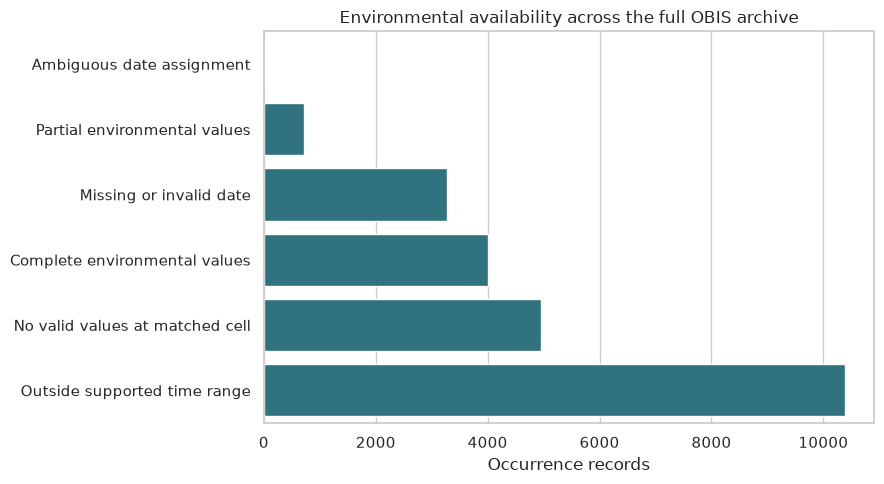

In [30]:
raster_status = full["raster_match_status"].value_counts(dropna=False)
integration_profile = pd.DataFrame({
    "Integration measure": [
        "OBIS rows in full archive",
        "Rows with a raster-cell match",
        "Unique source raster cells occupied",
        "Environmental grid size",
    ],
    "Count or size": [
        len(full),
        raster_status.get("matched", 0),
        full["raster_cell_id"].nunique(),
        f'{integration_manifest["spatial_grid"]["rows"]} × '
        f'{integration_manifest["spatial_grid"]["columns"]}',
    ],
})
display(integration_profile)

coverage_names = {
    "complete_environmental_values": "Complete environmental values",
    "partial_environmental_values": "Partial environmental values",
    "no_valid_source_values_at_cell": "No valid values at matched cell",
    "outside_supported_time_range": "Outside supported time range",
    "missing_or_invalid_date": "Missing or invalid date",
    "ambiguous_date_assignment": "Ambiguous date assignment",
}
coverage_all = (
    full["environmental_coverage_status"]
    .value_counts()
    .rename_axis("Source status")
    .rename("Records")
    .reset_index()
)
coverage_all["Integration outcome"] = coverage_all["Source status"].map(coverage_names)
coverage_all = coverage_all.sort_values("Records", ascending=True)
display(coverage_all[["Integration outcome", "Records"]])

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=coverage_all, x="Records", y="Integration outcome",
            ax=ax, color="#237b8b")
ax.set(title="Environmental availability across the full OBIS archive",
       xlabel="Occurrence records", ylabel="")
plt.tight_layout()
plt.show()

## 11. Temporal subset and environmental coverage

The temporal dataset retains 9,681 records with supported 2000–2026 source periods. Coverage classes describe source values at the assigned raster cells. The comparison below shows how the subsequent Policy B spatial filter changes the period counts.

,Temporal OBIS,Policy B candidates
analysis_period,,
2000-2009,651,376
2010-2019,2564,596
2020-2026,6466,1381


,Complete,Partial,No valid values
analysis_period,,,
2000-2009,331,109,211
2010-2019,872,200,1492
2020-2026,2807,403,3256


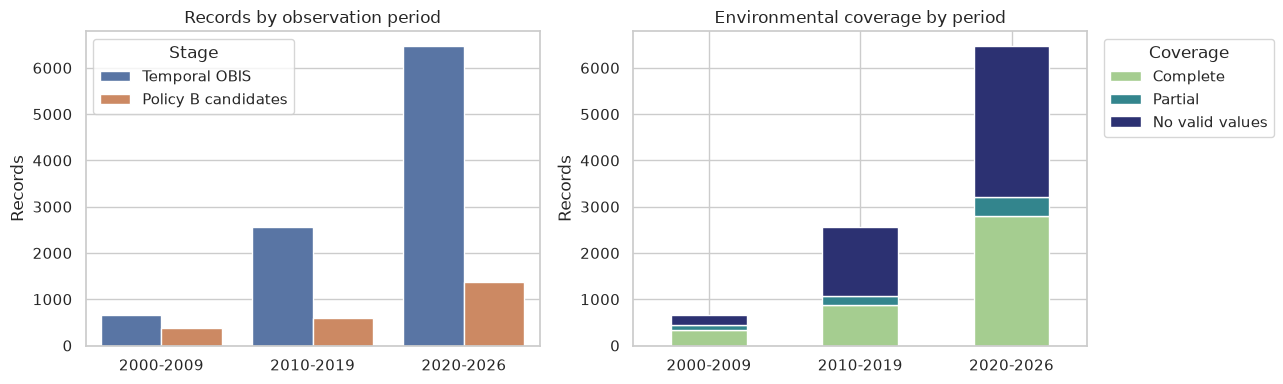

In [31]:
periods = ["2000-2009", "2010-2019", "2020-2026"]
period_counts = pd.DataFrame({
    "Temporal OBIS": temporal["analysis_period"].value_counts().reindex(periods),
    "Policy B candidates": marine["analysis_period"].value_counts().reindex(periods),
}).fillna(0).astype(int)
display(period_counts)

coverage_by_period = pd.crosstab(
    temporal["analysis_period"], temporal["environmental_coverage_status"]
).reindex(
    index=periods,
    columns=[
        "complete_environmental_values",
        "partial_environmental_values",
        "no_valid_source_values_at_cell",
    ],
    fill_value=0,
)
coverage_by_period.columns = ["Complete", "Partial", "No valid values"]
display(coverage_by_period)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
period_plot = period_counts.rename_axis("Period").reset_index().melt(
    id_vars="Period", var_name="Stage", value_name="Records"
)
sns.barplot(data=period_plot, x="Period", y="Records", hue="Stage", ax=axes[0])
axes[0].set(title="Records by observation period", xlabel="", ylabel="Records")
axes[0].tick_params(axis="x", rotation=0)

coverage_by_period.plot(kind="bar", stacked=True, ax=axes[1], colormap="crest")
axes[1].set(title="Environmental coverage by period", xlabel="", ylabel="Records")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Coverage", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

## 12. Policy B screening and earlier strict-policy comparison

Policy B first checks the recorded point against the GSHHG water polygon and applies exact OBIS quality-flag exclusions. The table distinguishes overlapping flags from their union. The comparison chart shows the former strict count and current candidate count; the increase is not scientific approval.

,Screening measure,Records
0,Temporal input,9681
1,Water-centre matches before quality flags,2815
2,Flagged water-centre points excluded,462
3,Policy B water-centre candidates,2353
4,Unflagged points outside water excluded,904
5,ON_LAND flags,6423
6,MARINE_UNSURE flags,41
7,Both flags,40
8,Either flag (overlap counted once),6424
9,Boundary or invalid-coordinate exclusions,0


,Policy,Water-centre candidates
0,D-053 strict,1299
1,D-054 Policy B,2353


Additional Policy B candidates: 1054


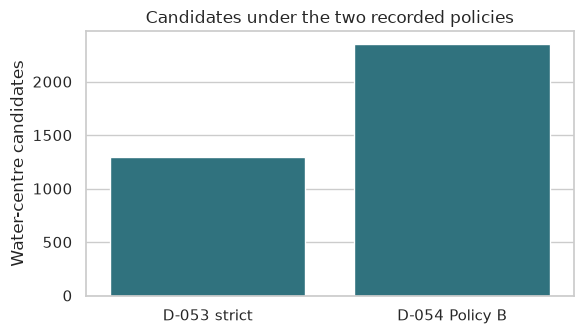

In [32]:
marine_report = policy_report["marine"]
flag_counts = marine_report["flag_exclusions"]
screening = pd.DataFrame({
    "Screening measure": [
        "Temporal input",
        "Water-centre matches before quality flags",
        "Flagged water-centre points excluded",
        "Policy B water-centre candidates",
        "Unflagged points outside water excluded",
        "ON_LAND flags",
        "MARINE_UNSURE flags",
        "Both flags",
        "Either flag (overlap counted once)",
        "Boundary or invalid-coordinate exclusions",
    ],
    "Records": [
        marine_report["input_temporal_rows"],
        marine_report["water_centres_before_quality_flags"],
        marine_report["flagged_water_centres_excluded"],
        marine_report["retained_rows"],
        marine_report["unflagged_outside_water_centres_excluded"],
        flag_counts["on_land"],
        flag_counts["marine_unsure"],
        flag_counts["both"],
        flag_counts["union"],
        marine_report["boundary_points_excluded"] + marine_report["invalid_coordinates"],
    ],
})
display(screening)

strict_rows = next(
    item["shape"][0]
    for item in policy_report["retired_strict_policy_datasets"]
    if item["path"].endswith("marine_observations.parquet")
)
policy_comparison = pd.DataFrame({
    "Policy": ["D-053 strict", "D-054 Policy B"],
    "Water-centre candidates": [strict_rows, marine_report["retained_rows"]],
})
display(policy_comparison)
print("Additional Policy B candidates:", marine_report["retained_rows"] - strict_rows)

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(data=policy_comparison, x="Policy", y="Water-centre candidates",
            ax=ax, color="#237b8b")
ax.set(title="Candidates under the two recorded policies",
       xlabel="", ylabel="Water-centre candidates")
plt.tight_layout()
plt.show()

## 13. Map of temporal observations and water-centre candidates

The map places all temporally eligible points in grey and overlays Policy B candidates by their recorded uncertainty category. The pale polygon is the saved GSHHG marine-water reference. This shows point-location evidence only; uncertainty footprints are not drawn as verified marine polygons.

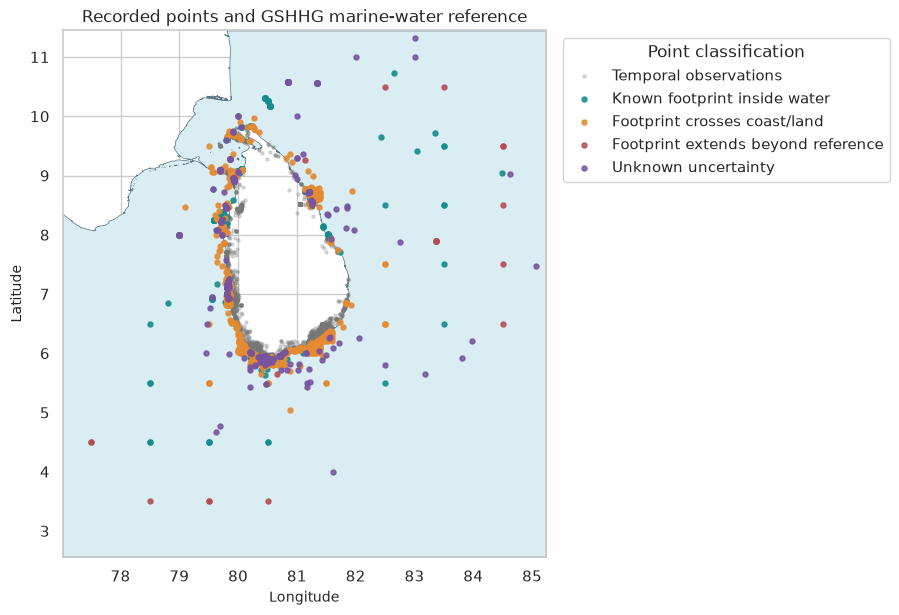

In [34]:
confidence_labels = {
    "known_footprint_marine": "Known footprint inside water",
    "known_footprint_crosses_coast_or_land": "Footprint crosses coast/land",
    "known_footprint_outside_reference_extent": "Footprint extends beyond reference",
    "unknown_uncertainty": "Unknown uncertainty",
    "invalid_uncertainty": "Invalid uncertainty",
}
confidence_colors = {
    "known_footprint_marine": "#168c8c",
    "known_footprint_crosses_coast_or_land": "#e58b32",
    "known_footprint_outside_reference_extent": "#b34e55",
    "unknown_uncertainty": "#7654a1",
    "invalid_uncertainty": "#444444",
}

fig, ax = plt.subplots(figsize=(8, 7))
water_reference.plot(ax=ax, color="#d9edf2", edgecolor="#5a7680", linewidth=0.5)
ax.scatter(temporal.geometry.x, temporal.geometry.y, s=5, color="#777777",
           alpha=0.24, label="Temporal observations", rasterized=True)

for category, label in confidence_labels.items():
    points = marine[marine["marine_position_confidence"] == category]
    if not points.empty:
        ax.scatter(points.geometry.x, points.geometry.y, s=13,
                   color=confidence_colors[category], alpha=0.85,
                   label=label, rasterized=True)

bounds = water_reference.total_bounds
ax.set_xlim(bounds[0], bounds[2])
ax.set_ylim(bounds[1], bounds[3])
ax.set(title="Recorded points and GSHHG marine-water reference",
       xlabel="Longitude", ylabel="Latitude")
ax.legend(title="Point classification", loc="upper left",
          bbox_to_anchor=(1.02, 1), frameon=True)
plt.tight_layout()
plt.show()

## 14. Positional uncertainty among Policy B candidates

The known footprint classes remain distinct from the point-in-water test. Unknown uncertainty is not treated as zero. D-054 retained centre-in-water candidates even when the known footprint crosses land/coast or extends beyond the reference.

,Uncertainty category,Records
0,Known footprint inside water,709
1,Footprint crosses coast/land,1025
2,Footprint extends beyond reference,29
3,Unknown uncertainty,590
4,Invalid uncertainty,0


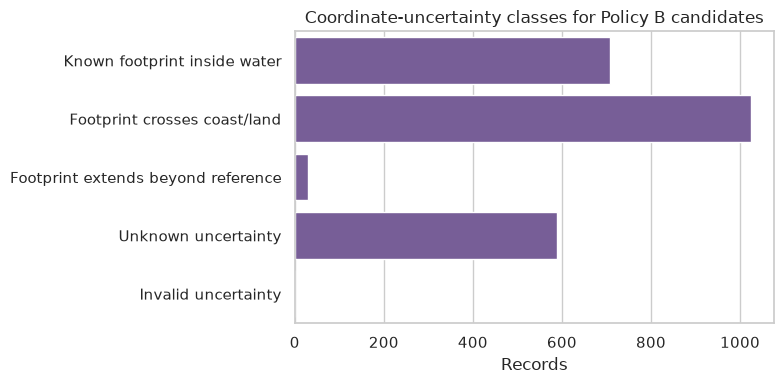

In [35]:
confidence_counts = marine["marine_position_confidence"].value_counts()
confidence_order = list(confidence_labels)
confidence_table = pd.DataFrame({
    "Uncertainty category": [confidence_labels[key] for key in confidence_order],
    "Records": [confidence_counts.get(key, 0) for key in confidence_order],
})
display(confidence_table)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=confidence_table, x="Records", y="Uncertainty category",
            ax=ax, color="#7654a1")
ax.set(title="Coordinate-uncertainty classes for Policy B candidates",
       xlabel="Records", ylabel="")
plt.tight_layout()
plt.show()

## 15. Grid observations and species/cell/period summary

Each qualifying candidate remains an individual grid observation. Grouped rows represent species-rank identifiers within a raster cell and analysis period. The bars show records, eligible species-rank records and grouped summary rows separately by period.

,Grid observations,Species-rank records,Summary groups
2000-2009,376,172,90
2010-2019,596,513,414
2020-2026,1381,1324,885


,Measure,Count
0,Individual grid observations,2353
1,Distinct occupied cells,362
2,Species-rank records with identifiers,2009
3,Distinct species identifiers,501
4,Species/cell/period summary rows,1389
5,Observations not represented in that summary,344


Summary occurrence counts reconcile: True


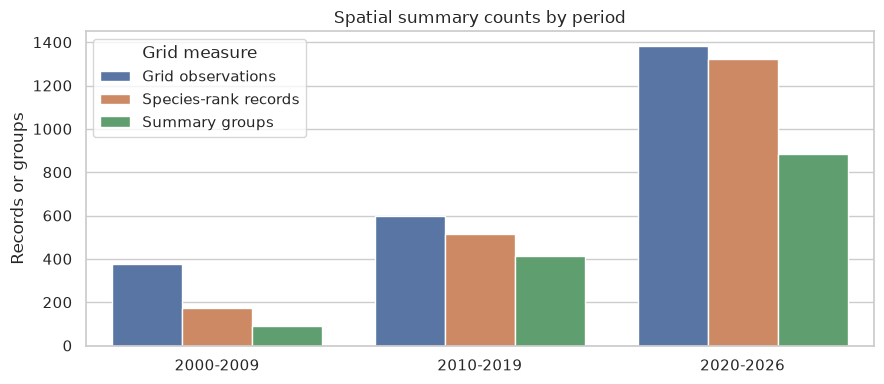

In [36]:
grid_report = policy_report["grid_and_species"]
grid_by_period = pd.DataFrame({
    "Grid observations": pd.Series(grid_report["records_by_period"]),
    "Species-rank records": pd.Series(grid_report["species_rank_records_by_period"]),
    "Summary groups": pd.Series(grid_report["summary_rows_by_period"]),
}).reindex(periods).fillna(0).astype(int)
display(grid_by_period)

grid_totals = pd.DataFrame({
    "Measure": [
        "Individual grid observations",
        "Distinct occupied cells",
        "Species-rank records with identifiers",
        "Distinct species identifiers",
        "Species/cell/period summary rows",
        "Observations not represented in that summary",
    ],
    "Count": [
        grid_report["gridded_observations"],
        grid_report["distinct_occupied_cells"],
        grid_report["species_rank_records_with_identifier"],
        grid_report["distinct_species_identifiers"],
        grid_report["species_cell_period_summary_rows"],
        grid_report["ungrouped_observations"],
    ],
})
display(grid_totals)
print("Summary occurrence counts reconcile:",
      grid_report["summary_counts_reconcile"])

fig, ax = plt.subplots(figsize=(9, 4))
grid_plot = grid_by_period.rename_axis("Period").reset_index().melt(
    id_vars="Period", var_name="Grid measure", value_name="Records"
)
sns.barplot(data=grid_plot, x="Period", y="Records", hue="Grid measure", ax=ax)
ax.set(title="Spatial summary counts by period", xlabel="", ylabel="Records or groups")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 16. Source metadata issues and quarantined examples

The independent source audit recorded unresolved source-semantic issues. Affected values remain null where correcting them would require guessing. The examples below come from the saved audit report; this notebook does not reopen NetCDF products or repeat the audit.

In [37]:
display(pd.DataFrame({
    "Recorded source issue": source_audit["source_metadata_issues"]
}))

examples = pd.DataFrame(source_audit["temperature_examples"])
temperature_examples = examples[
    examples["variable"].isin(["tas_mean", "tas_range"])
]
display(temperature_examples[
    ["variable", "period", "raw_decoded", "cleaned_decoded",
     "final_value", "source_units", "quarantined"]
])

,Recorded source issue
0,Raw and cleaned baseline absolute tas declare ...
1,Original tas_range has -273.15 offset relative...
2,Original SSP245 clt_sd exceeds fraction scale:...
3,Concentration units and baseline averaging win...


,variable,period,raw_decoded,cleaned_decoded,final_value,source_units,quarantined
6,tas_mean,baseline_2000,26.724735,26.724735,NaN,K,True
7,tas_mean,baseline_2010,27.318542,27.318542,NaN,K,True
10,tas_range,baseline_2000,-270.134128,-270.134128,NaN,K,True
11,tas_range,baseline_2010,-269.941407,-269.941407,NaN,K,True
15,tas_mean,ssp245_2020,26.975558,26.975558,26.975558,degree_C,False
17,tas_range,ssp245_2020,-268.514198,-268.514198,NaN,degree_C,True


## 17. Final read-only checks and boundaries

The checks below compare the cleaned OBIS file and full GeoParquet with their recorded fingerprints, confirm all five current outputs match the execution report and review the saved integration and independent-verification results. The independent NetCDF audit is summarized from its existing record, not rerun.

In [38]:
full_path = DATA / "full" / "integrated_observations.parquet"
obis_hash = hashlib.sha256(obis_path.read_bytes()).hexdigest()
full_hash = hashlib.sha256(full_path.read_bytes()).hexdigest()
grid_report = policy_report["grid_and_species"]

tables = {
    "full": full,
    "temporal": temporal,
    "marine": marine,
    "grid": grid,
    "summary": summary,
}
dimensions_match = all(
    len(frame) == policy_report["outputs"][name]["rows"]
    and len(frame.columns) == policy_report["outputs"][name]["columns"]
    for name, frame in tables.items()
)
original_fields_present = all(field in full.columns for field in obis_input.columns)

checks = pd.DataFrame({
    "Check": [
        "Cleaned OBIS input hash matches integration manifest",
        "Full archive hash matches integration manifest",
        "All five loaded tables match recorded dimensions",
        "All original OBIS columns are present in the integrated schema",
        "All 382 environmental definitions are recorded in every output",
        "GeoParquet 1.1.0, EPSG:4326 and ZSTD validation passed",
        "Summary occurrence counts reconcile",
        "Earlier independent environmental audit has zero value mismatches",
        "Earlier audit has zero null/fill and raster-coordinate discrepancies",
    ],
    "Pass": [
        obis_hash == integration_manifest["sources"]["obis_csv_sha256"],
        full_hash == policy_report["full_archive"]["manifest_sha256"],
        dimensions_match,
        original_fields_present
        and all(policy_report["validation"]["all_full_columns_preserved_in_individual_outputs"].values()),
        all(policy_report["validation"]["all_382_environmental_features_present"].values()),
        policy_report["validation"]["geo_parquet_1_1_epsg4326_zstd"],
        grid_report["summary_counts_reconcile"],
        source_audit["totals"]["mismatches"] == 0,
        source_audit["totals"]["null_fill_discrepancies"] == 0
        and source_audit["stored_raster_coordinate_discrepancies"] == 0,
    ],
})
display(checks)
assert checks["Pass"].all()

print("Earlier independent reader:", source_audit["reader"])
print("Source products checked:", source_audit["source_products_checked"])
print("Environmental columns checked:", source_audit["environmental_columns_checked"])
print("Environmental field positions checked:",
      f'{source_audit["totals"]["checked_positions"]:,}')
print("Earlier audit maximum absolute difference:",
      source_audit["maximum_absolute_difference"])

,Check,Pass
0,Cleaned OBIS input hash matches integration ma...,True
1,Full archive hash matches integration manifest,True
2,All five loaded tables match recorded dimensions,True
3,All original OBIS columns are present in the i...,True
4,All 382 environmental definitions are recorded...,True
5,"GeoParquet 1.1.0, EPSG:4326 and ZSTD validatio...",True
6,Summary occurrence counts reconcile,True
7,Earlier independent environmental audit has ze...,True
8,Earlier audit has zero null/fill and raster-co...,True


Earlier independent reader: netCDF4 1.7.4
Source products checked: 106
Environmental columns checked: 382
Environmental field positions checked: 8,927,722
Earlier audit maximum absolute difference: 0.0


## 18. References and next-step context

- [OBIS cleaning record](../../docs/records/2026-10-11-obis-area-230-cleaning.md)
- [Bio-ORACLE cleaning record](../../docs/records/2026-10-11-bio-oracle-cleaning.md)
- [Integration manifest](../../docs/records/2026-10-16-integration-manifest.json) and [integration summary](../../docs/records/2026-10-16-integration-summary.md)
- [Bio-ORACLE variable catalogue](../../docs/records/2026-10-16-integration-variable-catalog.md)
- [Independent environmental verification](../../docs/records/2026-10-16-independent-environmental-verification.md)
- [GSHHG marine-water reference](../../docs/records/2026-10-16-gshhg-marine-reference.json)
- [D-054 Policy B decision](../../docs/records/2026-10-16-decision-policy-b-marine-water-centre.md) and [execution report](../../docs/records/2026-10-16-policy-b-execution-report.md)
- [Script 08](../../src/data_preparation/08_integrate_spatiotemporal_data.py) and [Script 09](../../src/data_preparation/09_filter_and_grid_data.py)
- [Project requirements](../../PROJECT_REQUIREMENTS.md), [project scope](../../docs/project/project-overview-and-scope.md) and [current readiness](../../docs/project/repository-readiness-and-alignment.md)

Before any modelling preparation, review the environmental source quarantines, candidate species, uncertainty classes, intended spatial domain, target/background design and spatial validation. None of those decisions is completed by this integration notebook.